# Laser resonator modes by field tracing

Why does a laser emit a clean Gaussian beam, or a doughnut, or a messy
multimode beam? The answer lies in the resonator. Light bounces between
the mirrors many hundreds of times, and only field distributions that
reproduce themselves after a round trip survive: the **transverse modes**.
Notebook 08 (ABCD matrices) found the Gaussian mode of a stable resonator
from the ABCD matrix of the round trip, and
notebook 142 (laser fundamentals) dealt with gain, losses and the longitudinal modes. Both
assume infinitely large mirrors. Real mirrors, rods and apertures are
finite, they diffract, and that decides which transverse modes lase.

Fox and Li (1961) answered the question numerically, on one of the first
large computer runs in optics: start with any field, propagate it from
mirror to mirror with the Fresnel diffraction integral, cut it at the
mirror edges, and repeat. After a few hundred transits the field stops
changing. It has become the mode with the lowest loss, and the power it
loses per round trip is the **diffraction loss**. Mathematically the mode
is an eigenfunction of the round-trip operator $K$,

$$K E = \gamma E,$$

with the complex eigenvalue $\gamma$: $1 - |\gamma|^2$ is the power lost
per round trip, and the phase of $\gamma$ beyond the plane wave phase
$2kL$ is the Gouy phase that shifts the resonance frequencies of the
transverse modes.

`pyoptics.resonators` writes the round trip as a field tracing chain
(`pyoptics.fieldtrace`; mirrors as thin lenses $f = R/2$, apertures,
intracavity elements) and finds its eigenmodes in two ways:
`fox_li()` iterates like Fox and Li, `eigenmodes()` diagonalizes the
round trip and gives many modes at once. This notebook goes through

1. the Fox–Li iteration for plane mirrors,
2. diffraction losses of plane-parallel and confocal resonators versus the
   Fresnel number, checked against the prolate spheroidal functions,
3. the Hermite–Gaussian modes of a stable resonator and their frequencies,
4. selecting the fundamental mode with an aperture,
5. a thermal lens that pushes a resonator towards the edge of stability,
6. an unstable resonator: geometric output coupling and its diffraction
   ripples.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fieldtrace as ft
from pyoptics import resonators as rs
from pyoptics import abcd

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

wl = 1.0e-3        # 1 µm, lengths in mm
L = 100.0          # mirror spacing

## 1. The Fox–Li iteration

Two plane mirrors of half width $a$ (strips, infinitely long in $y$: one
transverse dimension, as in the original paper), a distance $L$ apart.
The key parameter is the **Fresnel number** $N = a^2/(\lambda L)$, the
number of Fresnel zones that a mirror covers seen from the other one.
Fox and Li's famous example has $N = 6.25$.

`rs.round_trip(L, R1, R2, a1, a2)` builds the round trip as a chain. Its
free-space steps (`rs.GridPropagate`) propagate the field with the
angular spectrum on the fixed grid of the reference plane: a resonator
needs the same grid on every pass, and the hard mirror edges diffract
light into wide angles that leave the cavity anyway. We start with a
uniform field and watch the loss per round trip settle:

Chain([grid propagate 100, mirror 2 aperture, grid propagate 100, mirror 1 aperture])


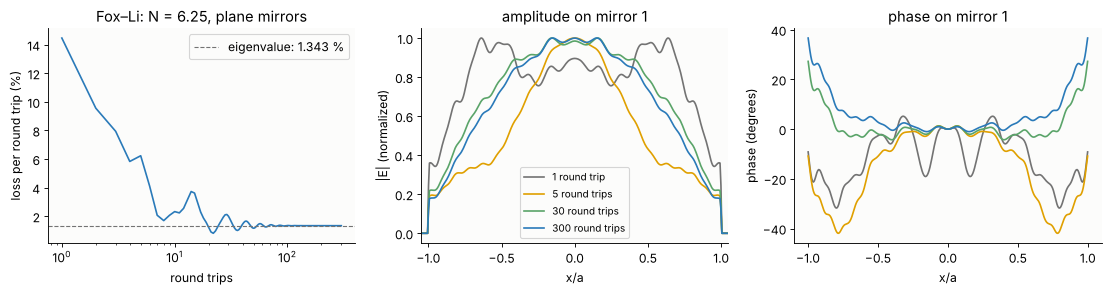

lowest losses per round trip: 1.34 %, 5.42 %, 11.16 %


In [2]:
N_F = 6.25
a = np.sqrt(N_F*wl*L)
x = np.linspace(-1.6*a, 1.6*a, 512)
plane = rs.round_trip(L, a1=a, a2=a)
print(plane)

start = ft.Field(np.where(np.abs(x) <= a, 1.0, 0.0), x, None, wl)
snapshots = {}
for n_iter in (1, 5, 30, 300):
    mode, losses = rs.fox_li(plane, x, None, wl, n_iter=n_iter, start=start, tol=0, alpha_ref=(0, 0))
    snapshots[n_iter] = mode
exact = rs.eigenmodes(plane, x, None, wl, n_modes=3)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(np.arange(1, len(losses) + 1), 100*losses, color=BLUE)
ax[0].axhline(100*exact[0].loss, color=GREY, ls="--", lw=1, label="eigenvalue: {:.3f} %".format(100*exact[0].loss))
ax[0].set_xscale("log"); ax[0].set_xlabel("round trips"); ax[0].set_ylabel("loss per round trip (%)")
ax[0].legend(); ax[0].set_title("Fox–Li: N = 6.25, plane mirrors")
for (n_iter, m), c in zip(snapshots.items(), [GREY, ORANGE, GREEN, BLUE]):
    A = m.field.scalar_amplitude
    A = A/np.abs(A).max()
    ax[1].plot(x/a, np.abs(A), color=c, label="{} round trip{}".format(n_iter, "s" if n_iter > 1 else ""))
    ph = np.angle(A*np.exp(-1j*np.angle(A[len(x)//2])))
    sel = np.abs(x) <= a
    ax[2].plot(x[sel]/a, np.degrees(ph[sel]), color=c)
ax[1].set_xlim(-1.05, 1.05); ax[1].set_xlabel("x/a"); ax[1].set_ylabel("|E| (normalized)")
ax[1].legend(fontsize=9); ax[1].set_title("amplitude on mirror 1")
ax[2].set_xlabel("x/a"); ax[2].set_ylabel("phase (degrees)"); ax[2].set_title("phase on mirror 1")
plt.tight_layout(); plt.show()
print("lowest losses per round trip: " + ", ".join("{:.2f} %".format(100*m.loss) for m in exact))

The uniform start field carries strong diffraction ripples from the
mirror edges; they die out over a few dozen transits, and after a few
hundred the field is the lowest-loss mode: a smooth, nearly cosine-shaped
amplitude that falls to a small value at the edges, with a slightly curved
phase front, just as in Fox and Li's paper. The loss settles at 1.3 % per
round trip (0.67 % per transit). The iteration converges at the rate
$|\gamma_1/\gamma_0|$ per round trip; with modes this close in loss it
takes hundreds of round trips, which is why `rs.eigenmodes()` (a direct
diagonalization) is the faster tool.

## 2. Losses versus the Fresnel number: plane and confocal resonators

The losses fall quickly with the Fresnel number, and they depend on the
mirror curvature. In the **confocal** resonator ($R_1 = R_2 = L$) the
round trip is a pair of Fourier transforms, its modes are the prolate
spheroidal functions of Slepian and Pollak, and the one-transit
eigenvalues $\sigma_n$ follow from a small integral eigenvalue problem
(`rs.confocal_strip_eigenvalues()`, computed by quadrature). The confocal
modes are confined towards the axis, so their losses are orders of
magnitude below those of the plane-parallel resonator:

16 resonators in 6 s


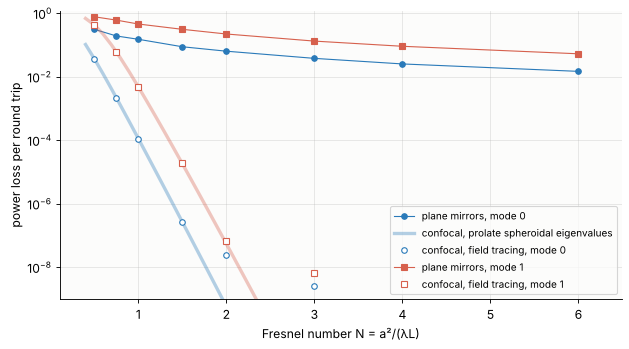

In [3]:
Ns = np.array([0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0])
t0 = time.time()
loss_plane, loss_conf = [], []
for N_F in Ns:
    a = np.sqrt(N_F*wl*L)
    x = np.linspace(-1.6*a, 1.6*a, 384)
    loss_plane.append([m.loss for m in rs.eigenmodes(rs.round_trip(L, a1=a, a2=a), x, None, wl, n_modes=2)])
    loss_conf.append([m.loss for m in rs.eigenmodes(rs.round_trip(L, L, L, a, a), x, None, wl, n_modes=2)])
loss_plane, loss_conf = np.array(loss_plane), np.array(loss_conf)
print("{} resonators in {:.0f} s".format(2*len(Ns), time.time() - t0))

NN = np.linspace(0.4, 6.2, 60)
ref = np.array([1 - np.abs(rs.confocal_strip_eigenvalues(n, 2))**4 for n in NN])
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, (c, ls) in enumerate([(BLUE, "o"), (RED, "s")]):
    ax.semilogy(Ns, loss_plane[:, j], ls + "-", color=c, ms=5, lw=1,
                label="plane mirrors, mode {}".format(j))
    ax.semilogy(NN, ref[:, j], color=c, lw=3, alpha=0.35,
                label="confocal, prolate spheroidal eigenvalues" if j == 0 else None)
    ax.semilogy(Ns, loss_conf[:, j], ls, color=c, ms=5, mfc="white",
                label="confocal, field tracing, mode {}".format(j))
ax.set_xlabel("Fresnel number N = a²/(λL)"); ax.set_ylabel("power loss per round trip")
ax.set_ylim(1e-9, 1.2); ax.legend(fontsize=9); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

The traced confocal losses (open symbols) lie on the prolate spheroidal
reference (thick lines) down to about $10^{-7}$; below that, the sampled
mirror edges set a numerical floor near $10^{-8}$ (a finer grid lowers
it). At $N = 2$ the
confocal fundamental mode loses less than $10^{-5}$ per round trip,
the plane-parallel resonator more than 3 %. A plane-parallel resonator
also needs perfectly parallel mirrors; that is why most lasers use curved
mirrors.

## 3. A stable resonator: Hermite–Gaussian modes and their frequencies

Two concave mirrors of radius $R = 200$ mm at $L = 100$ mm ($g_1 = g_2 =
0.5$) with circular apertures 2.3 times the Gaussian mode radius on the
mirrors. Now the field is two-dimensional, and `rs.eigenmodes()` switches
to the Arnoldi method (scipy's `eigs`), which needs only round trips, no
matrix:

6 modes of a 96 x 96 grid in 3 s
Gaussian mode on the mirrors: w = 0.1917 mm (abcd: 0.1917 mm)


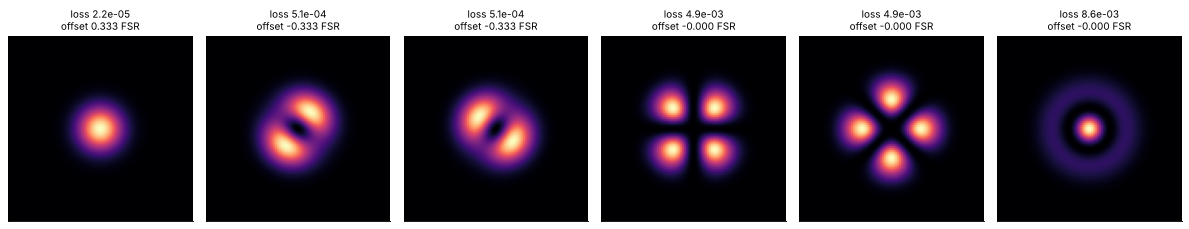

traced TEM00: second-moment radius 0.1917 mm
expected offsets (l + m + 1) arccos(sqrt(g1 g2))/pi = 0.333, -0.333, 0.000 FSR (modulo one FSR)


In [4]:
R = 200.0
w1, w2, w0, z1 = rs.gaussian_mode(L, R, R, wl)
a = 2.3*w1
x = np.linspace(-1.3*a, 1.3*a, 96)
t0 = time.time()
modes = rs.eigenmodes(rs.round_trip(L, R, R, a, a), x, x, wl, n_modes=6)
print("6 modes of a 96 x 96 grid in {:.0f} s".format(time.time() - t0))
print("Gaussian mode on the mirrors: w = {:.4f} mm (abcd: {:.4f} mm)".format(
    w1, abcd.beam_radius(abcd.eigenmode(abcd.compose(abcd.free_space(L), abcd.mirror(R),
                                                     abcd.free_space(L), abcd.mirror(R))), wl)))

fig, ax = plt.subplots(1, 6, figsize=(15, 2.9))
ext = [x[0]/w1, x[-1]/w1, x[0]/w1, x[-1]/w1]
for m, a_ in zip(modes, ax):
    I = m.field.irradiance()
    a_.imshow(I/I.max(), extent=ext, origin="lower", cmap="magma")
    a_.set_title("loss {:.1e}\noffset {:.3f} FSR".format(m.loss, rs.frequency_offsets([m], L)[0]),
                 fontsize=9)
    a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

X, Y = np.meshgrid(x, x)
I0 = modes[0].field.irradiance()
w_traced = 2*np.sqrt(np.sum(I0*X**2)/np.sum(I0))
print("traced TEM00: second-moment radius {:.4f} mm".format(w_traced))
theta = np.arccos(np.sqrt(0.25))
print("expected offsets (l + m + 1) arccos(sqrt(g1 g2))/pi = {:.3f}, {:.3f}, {:.3f} FSR "
      "(modulo one FSR)".format(*[np.mod(o*theta/np.pi + 0.5, 1) - 0.5 for o in (1, 2, 3)]))

The modes come out as the Gauss–Hermite/Gauss–Laguerre family, ordered by
loss: TEM$_{00}$, the degenerate pair of order one (TEM$_{01}$ and
TEM$_{10}$; any combination of the two is a mode too, so the solver returns
some rotated pair; `eigenmodes()` runs the Arnoldi method a second time with the
modes found so far deflated, since one run finds only one direction of a
degenerate pair), then the modes of
order two. With round apertures
the losses split the order-two family into the Laguerre–Gaussian modes:
the pair LG$_0^{\pm 2}$ (four lobes in any orientation) and the ring
mode LG$_1^0$ with its slightly higher loss. The TEM$_{00}$ radius agrees with the
ABCD prediction. The phase of each eigenvalue gives the frequency offset
of the mode from the longitudinal resonance, $(l + m + 1)\arccos(\pm\sqrt{g_1
g_2})/\pi$ free spectral ranges (modulo one FSR; `rs.frequency_offsets()`
wraps them to $\pm 1/2$): modes of the same order share a frequency, and
the orders are spaced by $1/3$ FSR here. With such
"degenerate" spacings (1/3, 1/2, ...) modes of different orders coincide in
frequency, which a laser designer usually avoids.

## 4. Selecting TEM$_{00}$ with an aperture

A laser oscillates on every mode whose round-trip gain exceeds its loss.
To make it run on TEM$_{00}$ alone, an aperture inside the cavity is made
just small enough to cost the higher modes, which are wider, much more
than the fundamental. In a half-symmetric resonator (plane mirror and
concave mirror $R = 500$ mm, the aperture at the plane mirror), the losses
of the first three modes versus the aperture radius in units of the
Gaussian beam radius $w$ there (strip mirrors; the trends are the same for
round apertures):

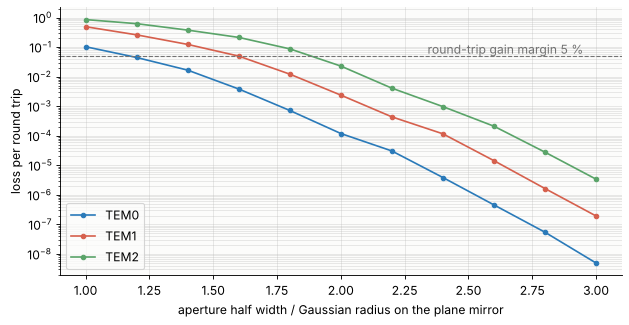

In [5]:
R2 = 500.0
w_plane = rs.gaussian_mode(L, np.inf, R2, wl)[0]
ratios = np.linspace(1.0, 3.0, 11)
losses = []
for r_ in ratios:
    a = r_*w_plane
    x = np.linspace(-1.3*a, 1.3*a, 256)
    ms = rs.eigenmodes(rs.round_trip(L, np.inf, R2, a1=a, a2=None), x, None, wl, n_modes=3)
    losses.append([m.loss for m in ms])
losses = np.array(losses)
fig, ax = plt.subplots(figsize=(8, 4.2))
for j, c in enumerate([BLUE, RED, GREEN]):
    ax.semilogy(ratios, losses[:, j], "o-", color=c, ms=4, label="TEM{}".format(j))
ax.axhline(0.05, color=GREY, ls="--", lw=1)
ax.text(2.95, 0.06, "round-trip gain margin 5 %", ha="right", color=GREY)
ax.set_xlabel("aperture half width / Gaussian radius on the plane mirror")
ax.set_ylabel("loss per round trip"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

With a gain margin of 5 % above the other losses, an aperture between
about 1.2 and 1.6 beam radii lets TEM$_0$ lase while TEM$_1$ stays below
threshold; smaller, and the fundamental mode is lost too; larger, and the
next mode joins in. Rules of thumb for the aperture size of TEM$_{00}$
lasers come from curves like these; the window is narrow, and a laser
with more gain needs a tighter aperture.

## 5. A thermal lens

A pumped laser rod heats up and becomes a lens, whose power grows with
the pump power. A resonator with two plane mirrors is not stable without
it; the thermal lens makes it stable, with an equivalent $g = 1 - L/(2f)$
for a lens in the middle, from a weak lens ($f \to \infty$, a huge mode)
to $f = L/4$ (the far edge of stability). Here: plane mirrors of 0.75 mm
half width, $L = 100$ mm, and the rod in the middle as a thin lens of
focal length $f$ with an aperture of 0.5 mm half width (`elements=[...]` in
`rs.round_trip()`; strips again). The left panel compares the mode radius
on the mirrors with the Gaussian mode of the ABCD round trip, the right one
shows the diffraction losses of the first two modes:

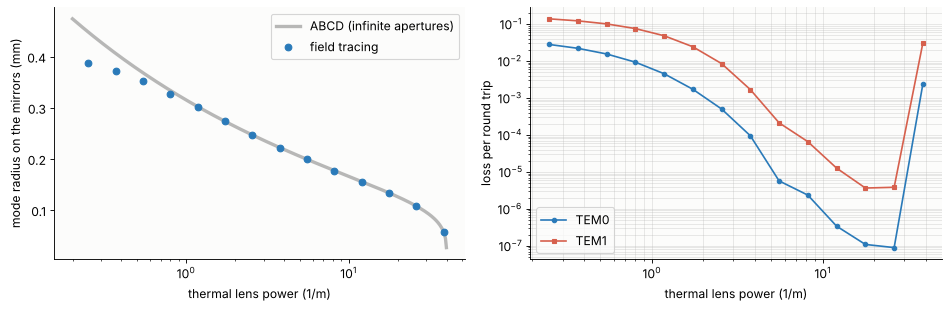

In [6]:
f_th = np.geomspace(4000.0, 26.0, 14)
x = np.linspace(-0.8, 0.8, 384)
h = abcd.free_space(L/2)


def abcd_radius(f):
    try:
        return abcd.beam_radius(abcd.eigenmode(abcd.compose(h, abcd.thin_lens(f), h, h,
                                                            abcd.thin_lens(f), h)), wl)
    except ValueError:
        return np.nan


def is_even(m):
    # the fundamental mode has no node: |sum E|^2/sum|E|^2 is largest
    A = m.field.scalar_amplitude
    return abs(A.sum())**2/np.sum(np.abs(A)**2)


w_traced, loss0, loss1 = [], [], []
for f in f_th:
    rod = [ft.Aperture(radius=0.5, label="rod"), ft.ThinLens(f)]
    ms = rs.eigenmodes(rs.round_trip(L, a1=0.75, a2=0.75, elements=rod), x, None, wl, n_modes=3)
    m0 = max(ms, key=is_even)
    I = np.abs(m0.field.scalar_amplitude)**2
    w_traced.append(2*np.sqrt(np.sum(I*x**2)/np.sum(I)))
    loss0.append(m0.loss)
    loss1.append(min(m.loss for m in ms if m is not m0))

ff = np.geomspace(5000, 25.05, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(1000/ff, [abcd_radius(f) for f in ff], color=GREY, lw=3, alpha=0.5,
           label="ABCD (infinite apertures)")
ax[0].plot(1000/f_th, w_traced, "o", color=BLUE, label="field tracing")
ax[0].set_xscale("log"); ax[0].set_xlabel("thermal lens power (1/m)")
ax[0].set_ylabel("mode radius on the mirrors (mm)"); ax[0].legend()
ax[1].loglog(1000/f_th, loss0, "o-", color=BLUE, ms=4, label="TEM0")
ax[1].loglog(1000/f_th, loss1, "s-", color=RED, ms=4, label="TEM1")
ax[1].set_xlabel("thermal lens power (1/m)"); ax[1].set_ylabel("loss per round trip")
ax[1].legend(); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

At low pump power the lens is weak, the mode is large, and the rod and
the mirrors clip it: high losses for all modes, and a small difference
between TEM$_0$ and TEM$_1$, so such a laser runs multimode. As the lens
gets stronger the mode shrinks and the losses fall by orders of magnitude.
Near the far edge of stability ($f \to L/4$, 40 m$^{-1}$) the mode on the
mirrors becomes tiny, but it is focused onto the mirrors and spreads out
at the rod, where the aperture clips it again. The output and the beam
quality of a solid-state laser change with the pump power for exactly
this reason; resonator designs for high power keep the laser inside the
stability range over the whole range of pump powers.

## 6. An unstable resonator

High-gain lasers (CO$_2$, excimer, chemical lasers) often use **unstable**
resonators. In a positive-branch confocal resonator a large concave mirror
and a small convex mirror share their focal point; a ray bounces outward,
its distance from the axis growing by the magnification $M = R_1/|R_2|$
per round trip, until it passes the edge of the small mirror and leaves
the cavity as an annular (here: two-strip) beam. Geometric optics predicts
the output coupling $1 - 1/M$ per round trip (strips; $1 - 1/M^2$ for
round mirrors), independent of the mirror size. Diffraction makes the loss
oscillate about this value with the **equivalent Fresnel number**
$N_{eq} = \frac{M-1}{2}\frac{a^2}{L\lambda}$ (Siegman, chapter 22):

R_small = -200 mm, R_big = 400 mm, magnification 2.00


37 resonators in 28 s


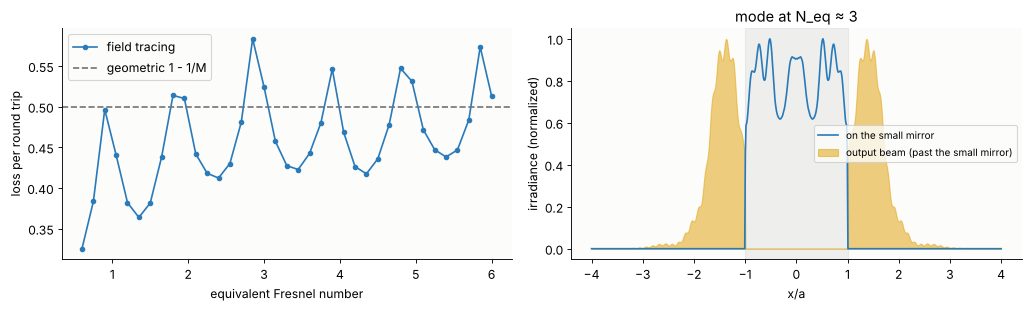

In [7]:
M_mag = 2.0
R_small, R_big = -2*L/(M_mag - 1), 2*L*M_mag/(M_mag - 1)
print("R_small = {:.0f} mm, R_big = {:.0f} mm, magnification {:.2f}".format(
    R_small, R_big, rs.unstable_magnification(L, R_small, R_big)))
a_vals = np.sqrt(np.linspace(0.6, 6.0, 37)*2*L*wl/(M_mag - 1))
Neq, loss_u = [], []
t0 = time.time()
for a in a_vals:
    x = np.linspace(-4*a, 4*a, 640)
    m = rs.eigenmodes(rs.round_trip(L, R_small, R_big, a1=a, a2=None), x, None, wl, n_modes=1)[0]
    Neq.append(rs.equivalent_fresnel_number(a, L, M_mag, wl))
    loss_u.append(m.loss)
    if np.isclose(Neq[-1], 3.0, atol=0.08):
        keep = (a, x, m)
print("{} resonators in {:.0f} s".format(len(a_vals), time.time() - t0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(Neq, loss_u, "o-", color=BLUE, ms=4, label="field tracing")
ax[0].axhline(rs.geometric_loss(M_mag, 1), color=GREY, ls="--", label="geometric 1 - 1/M")
ax[0].set_xlabel("equivalent Fresnel number"); ax[0].set_ylabel("loss per round trip")
ax[0].legend()
a, x, m = keep
E = m.field.scalar_amplitude
ax[1].plot(x/a, np.abs(E)**2/np.max(np.abs(E)**2), color=BLUE, label="on the small mirror")
f_out = ft.Chain([rs.GridPropagate(L), ft.ThinLens(R_big/2), rs.GridPropagate(L)]).run(m.field).field
Eo = f_out.scalar_amplitude
Io = np.abs(Eo)**2*(np.abs(x) > a)
ax[1].fill_between(x/a, Io/np.max(np.abs(Eo)**2), color=ORANGE, alpha=0.5,
                   label="output beam (past the small mirror)")
ax[1].axvspan(-1, 1, color=GREY, alpha=0.1)
ax[1].set_xlabel("x/a"); ax[1].set_ylabel("irradiance (normalized)")
ax[1].set_title("mode at N_eq ≈ 3"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

The loss oscillates about the geometric value with a period of one in
$N_{eq}$, as in Siegman's classic figures. The mode fills the small mirror (shaded), and the
output beam is the part of the collimated beam that passes it, two strips
here and a ring for round mirrors. Unstable resonators give a large mode
volume with a short cavity, at the price of a beam with a hole in the
near field.

## Summary

- A transverse mode is an eigenfunction of the round trip; with the round
  trip written as a field tracing chain, `rs.fox_li()` iterates it as Fox
  and Li did, and `rs.eigenmodes()` finds several modes directly (dense
  for strips, Arnoldi for 2D).
- The diffraction losses depend on the Fresnel number and the mirror
  curvature; the confocal results agree with the prolate spheroidal
  eigenvalues down to losses of about $10^{-7}$.
- Stable resonators give Hermite–Gaussian modes whose Gouy phases split
  their frequencies by $\arccos(\pm\sqrt{g_1 g_2})/\pi$ FSR per order.
- An aperture of a little more than one beam radius selects TEM$_{00}$;
  a thermal lens changes the mode size with the pump power, and the
  apertures turn that into losses at both ends of the stability range.
- Unstable resonators couple out $1 - 1/M$ (strips) or $1 - 1/M^2$ of the
  power geometrically, with diffraction ripples in $N_{eq}$.

References: A. G. Fox and T. Li, Bell Syst. Tech. J. 40, 453 (1961);
G. D. Boyd and J. P. Gordon, Bell Syst. Tech. J. 40, 489 (1961);
D. Slepian and H. O. Pollak, Bell Syst. Tech. J. 40, 43 (1961);
A. E. Siegman, *Lasers* (1986), chapters 19 to 23.

In [8]:
print("total run time: {:.0f} s".format(time.time() - t_start))

total run time: 53 s
